In [1]:
from skyfield.api import load, wgs84, Topos
import numpy as np
from datetime import datetime, timedelta
import pytz
from tqdm import tqdm
from matplotlib import pyplot as plt
from scipy.optimize import minimize
import satfunc

In [2]:
from sys import platform
if platform == "linux" or platform == "linux2":
    path = '/home/jidazhang/Desktop/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'
elif platform == "win32":
    path = 'D:\\Desktop\\study\\2023_summer\\starlink_ofdm\\AoA_Sim\\tles\\10_31\\STARLINK-6150.tle'
else:
    path = '/Users/ishani/UIUC/Research/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'

satellites = load.tle_file(path)
lat, lon = +40.11389690596162, -88.22484814695467
lnb = wgs84.latlon(lat, lon)
ts = load.timescale()
start_time = datetime(2023, 10, 31, 0, 0, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
stop_time = datetime(2023, 10, 31, 0, 1, 0, tzinfo=pytz.UTC)+timedelta(hours=5)

In [28]:
# generate ground truth elevation & azimuth
fs = 1e1
t = ts.utc(start_time)
duration = stop_time-start_time
n_list = np.arange(0, fs*duration.total_seconds(), 1).astype(int)

elevation, azimuth = np.empty(len(n_list)), np.empty(len(n_list))

for n in tqdm(n_list):
    dist = (satellites[0]-lnb).at(t)
    el, az, distance = dist.altaz()
    elevation[n], azimuth[n] = el.degrees, az.degrees
    # increment t which is ts.utc by 1000/fs milliseconds
    t = ts.utc(t.utc_datetime()+timedelta(milliseconds=1000/fs))

100%|██████████| 600/600 [00:00<00:00, 4866.58it/s]


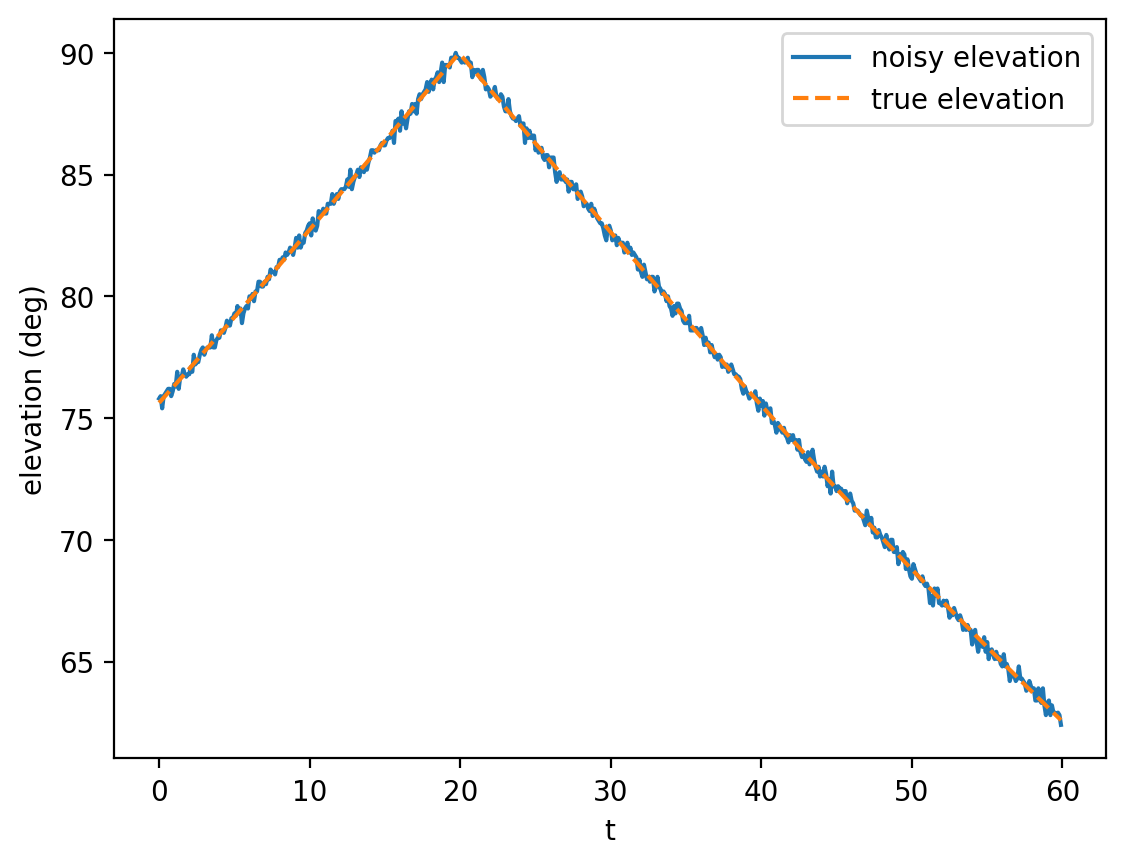

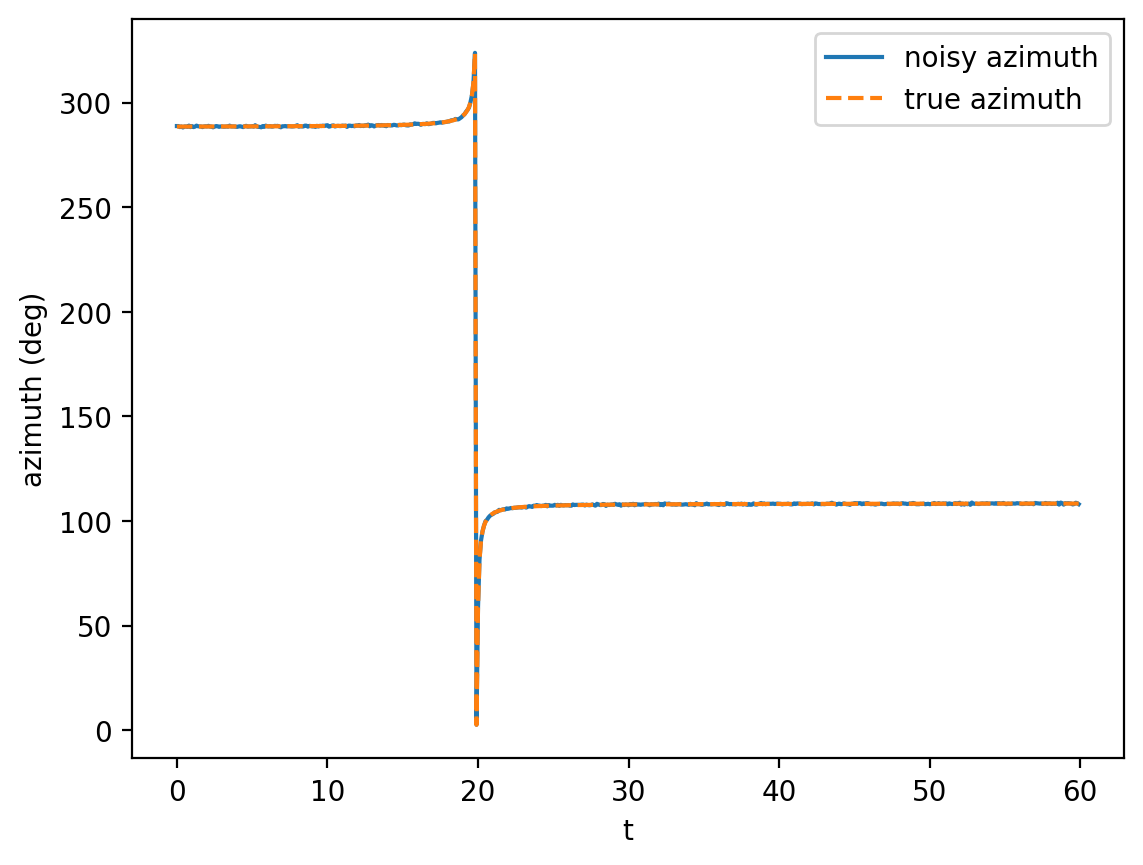

mean error of elevation:  0.16403764851876282
mean error of azimuth:  0.16224572625245529


In [29]:
# add noise and quantize the elevation and azimuth
elevation_clean = elevation.copy()
azimuth_clean = azimuth.copy()
elevation += np.random.normal(0, 0.2, len(elevation))
azimuth += np.random.normal(0, 0.2, len(azimuth))
quantization_precision = 0.1
elevation = np.round(elevation/quantization_precision)*quantization_precision
azimuth = np.round(azimuth/quantization_precision)*quantization_precision

# elevation
plt.plot(np.arange(0, 60, 1/fs), elevation, label='noisy elevation')
plt.plot(np.arange(0, 60, 1/fs), elevation_clean, label='true elevation', linestyle='--')
plt.xlabel('t')
plt.ylabel('elevation (deg)')
plt.legend()
plt.show()
# azimuth
plt.plot(np.arange(0, 60, 1/fs), azimuth, label='noisy azimuth')
plt.plot(np.arange(0, 60, 1/fs), azimuth_clean, label='true azimuth', linestyle='--')
plt.xlabel('t')
plt.ylabel('azimuth (deg)')
plt.legend()
plt.show()

# print the mean error between the noisy and true elevation and azimuth
print('mean error of elevation: ', np.mean(np.abs(elevation-elevation_clean)))
print('mean error of azimuth: ', np.mean(np.abs(azimuth-azimuth_clean)))

In [25]:
# Function to calculate the difference between observed and calculated azimuth and altitude
def difference(params, satellite, gt_azimuth, gt_elevation, t):
    observer = wgs84.latlon(params[0], params[1])
    dist = (satellite-observer).at(t)
    alt, az, _ = dist.altaz()
    return np.linalg.norm([alt.degrees-gt_elevation, az.degrees-gt_azimuth])

# Initial guess for observer's latitude and longitude
initial_guess = [0, 0]
bounds = [(-90, 90), (-180, 180)]
t = ts.utc(start_time)
estimated_latitude, estimated_longitude = np.empty(len(n_list)), np.empty(len(n_list))
for n in tqdm(n_list):
    result = minimize(difference, initial_guess, args=(satellites[0], azimuth[n], elevation[n], t), method='L-BFGS-B', bounds=bounds)
    estimated_latitude[n], estimated_longitude[n] = result.x
    initial_guess = result.x
    if np.abs(estimated_latitude[n]-lat) > 0.1 or np.abs(estimated_longitude[n]-lon) > 0.1:
        print(f"Estimated Latitude: {estimated_latitude[n]}, Estimated Longitude: {estimated_longitude[n]}")
        estimated_latitude[n], estimated_longitude[n] = lat, lon
    t = ts.utc(t.utc_datetime()+timedelta(milliseconds=1000/fs))

# print(f"Observer's Latitude: {optimized_latitude}, Observer's Longitude: {optimized_longitude}")

 34%|███▍      | 205/600 [00:04<00:09, 40.69it/s]

Estimated Latitude: 54.03855989296234, Estimated Longitude: -180.0


100%|██████████| 600/600 [00:13<00:00, 43.76it/s]


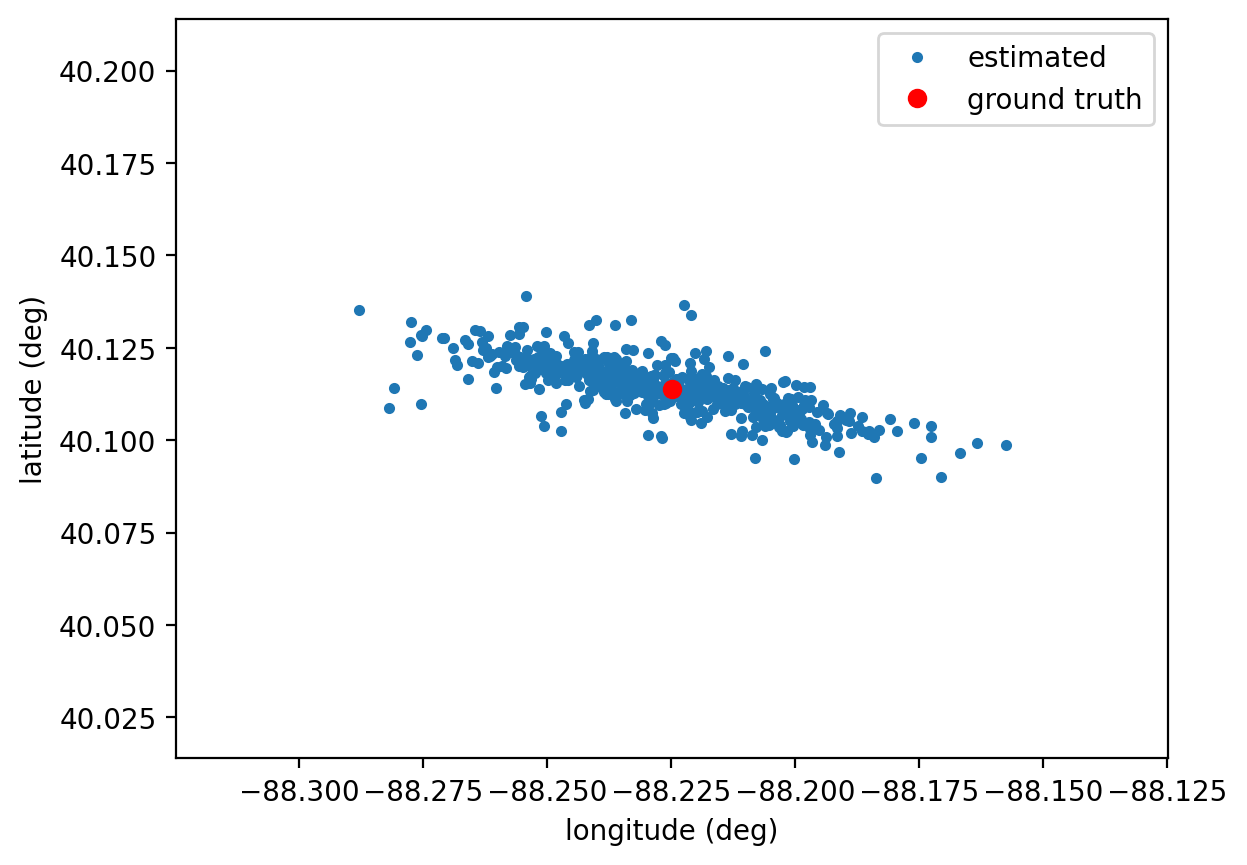

Localization Error = 103.81 meters


In [26]:
# draw a 2d scatter figure with the estimated latitude and longitude
plt.rcParams['figure.dpi'] = 200
plt.plot(estimated_longitude, estimated_latitude, '.', label='estimated')
plt.plot(lon, lat, 'ro', label='ground truth')
plt.xlabel('longitude (deg)')
plt.ylabel('latitude (deg)')
plt.xlim(lon-0.1, lon+0.1)
plt.ylim(lat-0.1, lat+0.1)
plt.legend()
plt.show()

distance = satfunc.calc_distance(np.mean(estimated_latitude), np.mean(estimated_longitude), lat, lon)
print(f'Localization Error = {distance:.2f} meters')